In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from sklearn.datasets import load_iris

iris = load_iris()

df = pd.DataFrame(iris.data, columns=iris.feature_names)
df["species"] = iris.target

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


#Dataset Exploration



* Identify:

1. Numeric variables

2. Categorical variables

* Print shape and data types.

In [3]:
# numeric_variables: sepal length (cm),  sepal width (cm),  petal length (cm),  petal width (cm)
# categorical_variables: species
print(df.shape)
print(df.dtypes)

(150, 5)
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
species                int64
dtype: object


#Central Tendency

1. Compute mean and median.

2. Compare them.

3. Which feature has largest mean?

In [4]:
df.mean()

,0
sepal length (cm),5.843333
sepal width (cm),3.057333
petal length (cm),3.758000
petal width (cm),1.199333
species,1.000000


In [5]:
df.median()

,0
sepal length (cm),5.80
sepal width (cm),3.00
petal length (cm),4.35
petal width (cm),1.30
species,1.00


In [8]:
mean=df.mean()
median=df.median()
print('\ncomparison:\n', mean - median)
print('\nlargest mean:', mean.idxmax())
# mean() and median() give similar (but not equal) results


comparison:
 sepal length (cm)    0.043333
sepal width (cm)     0.057333
petal length (cm)   -0.592000
petal width (cm)    -0.100667
species              0.000000
dtype: float64

largest mean: sepal length (cm)


#Variation
1. Compute variance and std.

2. Identify feature with highest variability.

3. Explain why.

In [9]:
variance=df.var()
std_dev=df.std()
print('Variance: \n',variance)
print('\nStandard Deviation: \n',std_dev)
print("\nHighest Variability:", df.std().idxmax())

Variance: 
 sepal length (cm)    0.685694
sepal width (cm)     0.189979
petal length (cm)    3.116278
petal width (cm)     0.581006
species              0.671141
dtype: float64

Standard Deviation: 
 sepal length (cm)    0.828066
sepal width (cm)     0.435866
petal length (cm)    1.765298
petal width (cm)     0.762238
species              0.819232
dtype: float64

Highest Variability: petal length (cm)


# IQR & Outliers

* Compute IQR.

* Detect outliers using IQR method:

1. Lower bound = Q1 − 1.5 × IQR

2. Upper bound = Q3 + 1.5 × IQR

* Count outliers.

In [11]:
features=df.drop(columns="species")
Q1=features.quantile(0.25)
Q3=features.quantile(0.75)

IQR=Q3-Q1

lower=Q1-1.5*IQR
upper=Q3+1.5*IQR

outliers=(features < lower) | (features > upper)
print("IQR:\n", IQR)
print("\nOutliers Count:\n", outliers.sum())

IQR:
 sepal length (cm)    1.3
sepal width (cm)     0.5
petal length (cm)    3.5
petal width (cm)     1.5
dtype: float64

Outliers Count:
 sepal length (cm)    0
sepal width (cm)     4
petal length (cm)    0
petal width (cm)     0
dtype: int64


/tmp/ipykernel_1131/2724802960.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([features[col] for col in features.columns],labels=features.columns)


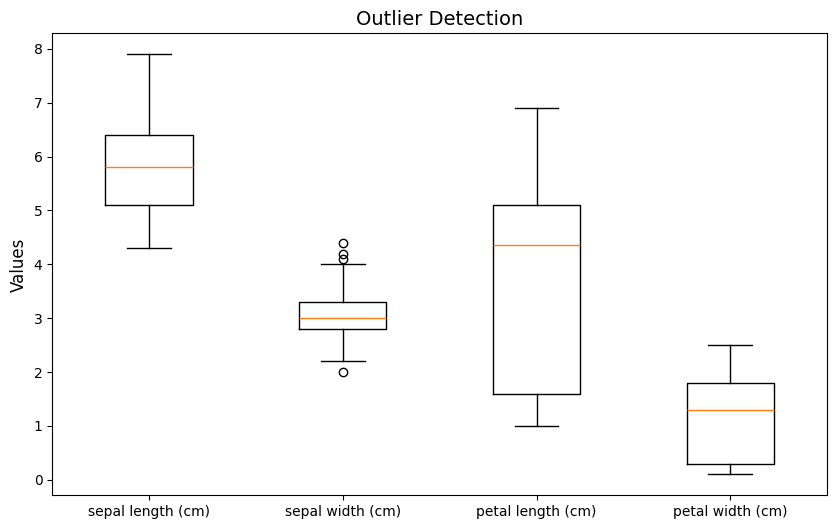

In [ ]:
features = df.drop(columns=['species'])

plt.figure(figsize=(10, 6))
plt.boxplot([features[col] for col in features.columns],labels=features.columns)
plt.title('Outlier Detection', fontsize=14)
plt.ylabel('Values', fontsize=12)
plt.show()

# Z-score

* Compute Z-scores.


In [14]:
from scipy.stats import zscore
z_scores = features.apply(zscore)
print(z_scores.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0          -0.900681          1.019004          -1.340227         -1.315444
1          -1.143017         -0.131979          -1.340227         -1.315444
2          -1.385353          0.328414          -1.397064         -1.315444
3          -1.506521          0.098217          -1.283389         -1.315444
4          -1.021849          1.249201          -1.340227         -1.315444


# Covariance & Correlation

* Compute covariance matrix.

* Compute correlation matrix.

* Identify:

1. Most positively correlated pair

2. Most negatively correlated pair

In [15]:
cov = features.cov()
corr = features.corr()

print('Covariance Matrix:\n', cov)
print('\nCorrelation Matrix:\n', corr)

pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()

print("\nMost Positive:", pairs.idxmax(), pairs.max())
print("Most Negative:", pairs.idxmin(), pairs.min())

Covariance Matrix:
                    sepal length (cm)  sepal width (cm)  petal length (cm)  \
sepal length (cm)           0.685694         -0.042434           1.274315   
sepal width (cm)           -0.042434          0.189979          -0.329656   
petal length (cm)           1.274315         -0.329656           3.116278   
petal width (cm)            0.516271         -0.121639           1.295609   

                   petal width (cm)  
sepal length (cm)          0.516271  
sepal width (cm)          -0.121639  
petal length (cm)          1.295609  
petal width (cm)           0.581006  

Correlation Matrix:
                    sepal length (cm)  sepal width (cm)  petal length (cm)  \
sepal length (cm)           1.000000         -0.117570           0.871754   
sepal width (cm)           -0.117570          1.000000          -0.428440   
petal length (cm)           0.871754         -0.428440           1.000000   
petal width (cm)            0.817941         -0.366126           0.962865 

# PCA Mini Task

* Compute covariance matrix.

* Compute eigenvalues.

* Identify principal direction.

* Explain which feature contributes most.

In [16]:
cov = features.cov()

eigenvalues, eigenvectors = np.linalg.eigh(cov)

index = np.argmax(eigenvalues)
principal_direction = eigenvectors[:, index]

print("Covariance Matrix:\n", cov)
print("\nEigenvalues:\n", eigenvalues)
print("\nPrincipal Direction:\n", principal_direction)
print("\nFeature Contributions:\n", abs(principal_direction))
print("\nMost Contributing Feature:", features.columns[np.argmax(abs(principal_direction))])

Covariance Matrix:
                    sepal length (cm)  sepal width (cm)  petal length (cm)  \
sepal length (cm)           0.685694         -0.042434           1.274315   
sepal width (cm)           -0.042434          0.189979          -0.329656   
petal length (cm)           1.274315         -0.329656           3.116278   
petal width (cm)            0.516271         -0.121639           1.295609   

                   petal width (cm)  
sepal length (cm)          0.516271  
sepal width (cm)          -0.121639  
petal length (cm)          1.295609  
petal width (cm)           0.581006  

Eigenvalues:
 [0.02383509 0.0782095  0.24267075 4.22824171]

Principal Direction:
 [-0.36138659  0.08452251 -0.85667061 -0.3582892 ]

Feature Contributions:
 [0.36138659 0.08452251 0.85667061 0.3582892 ]

Most Contributing Feature: petal length (cm)
